# Experiment: Handwritten Digit Recognition Using k-Nearest Neighbors (k-NN)
**Topic:** Supervised Non-Parametric Classification  
**Algorithm:** $k$-Nearest Neighbors Classifier  
**Dataset:** Scikit-Learn Optical Recognition of Handwritten Digits (`load_digits`)  
**Objective:** Classify $8 \times 8$ pixel grayscale handwritten digit images (classes 0–9) using distance-based instance similarity, evaluate feature scaling, tune the hyperparameter $k$, and analyze multi-class confusion dynamics.

---

## 1. Problem Statement & Theoretical Principles

The $k$-Nearest Neighbors ($k$-NN) algorithm is an instance-based (lazy learning) classifier. It makes no explicit assumptions regarding the underlying probability density distribution of the data (non-parametric).

### Distance Metrics

Given query instance $\mathbf{x} = (x_1, \dots, x_d)$ and training instance $\mathbf{z} = (z_1, \dots, z_d)$ in $\mathbb{R}^d$:

#### 1. Euclidean Distance ($L_2$ norm):
$$d_2(\mathbf{x}, \mathbf{z}) = \sqrt{\sum_{j=1}^{d} (x_j - z_j)^2}$$

#### 2. Manhattan Distance ($L_1$ norm):
$$d_1(\mathbf{x}, \mathbf{z}) = \sum_{j=1}^{d} |x_j - z_j|$$

#### 3. General Minkowski Distance ($L_p$ norm):
$$d_p(\mathbf{x}, \mathbf{z}) = \left( \sum_{j=1}^{d} |x_j - z_j|^p \right)^{\frac{1}{p}}$$

### Majority Voting Rule
For a query point $\mathbf{x}$, let $\mathcal{N}_k(\mathbf{x})$ denote the set of its $k$ nearest training neighbors. The predicted class $\hat{y}$ is determined via plurality voting:
$$\hat{y} = \arg\max_{c \in \{0, \dots, 9\}} \sum_{i \in \mathcal{N}_k(\mathbf{x})} \mathbb{I}(y_i = c)$$


In [1]:
# Import dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Loading & Inspection

The UCI ML Digits dataset contains 1,797 samples of normalized $8 \times 8$ grayscale images extracted from pre-printed forms.


In [2]:
# Load the digits dataset
digits = load_digits()
X = digits.data
y = digits.target

print(f"Dataset Shape: {X.shape} (1797 samples, 64 features per sample)")
print(f"Target Classes: {np.unique(y)}")
print(f"Feature Value Range: [{X.min():.1f}, {X.max():.1f}] (grayscale integer intensities)")

# Class frequency verification
class_counts = pd.Series(y).value_counts().sort_index()
print("\nSamples per digit class:")
print(class_counts.to_dict())


Dataset Shape: (1797, 64) (1797 samples, 64 features per sample)
Target Classes: [0 1 2 3 4 5 6 7 8 9]
Feature Value Range: [0.0, 16.0] (grayscale integer intensities)

Samples per digit class:
{0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


### Display Sample Digits
We visualize representative digit images across the 10 classes.


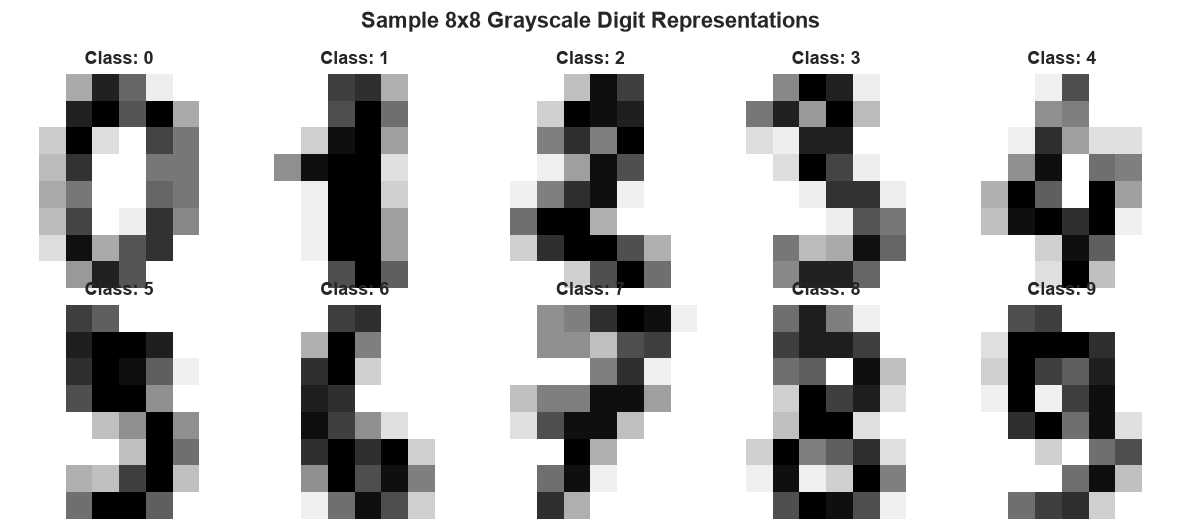

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for idx, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[idx], cmap='gray_r', interpolation='nearest')
    ax.set_title(f"Class: {digits.target[idx]}", fontsize=11, fontweight='bold')
    ax.axis('off')
plt.suptitle("Sample 8x8 Grayscale Digit Representations", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Train-Test Splitting & Data Scaling

We partition the dataset into 80% training and 20% testing sets using stratified sampling to preserve balanced class representations.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training Instances: {X_train.shape[0]}")
print(f"Testing Instances:  {X_test.shape[0]}")

# Scale pixel features between 0.0 and 1.0
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Training Instances: 1437
Testing Instances:  360


## 4. Hyperparameter Tuning: Optimal Choice of $k$

We systematically evaluate values of $k \in [1, 15]$ using 5-fold cross-validation on the training set to identify the optimal neighborhood size that balances variance and bias.


Optimal k identified via 5-Fold Cross-Validation: k = 1
Cross-Validation Accuracy at optimal k: 98.96%


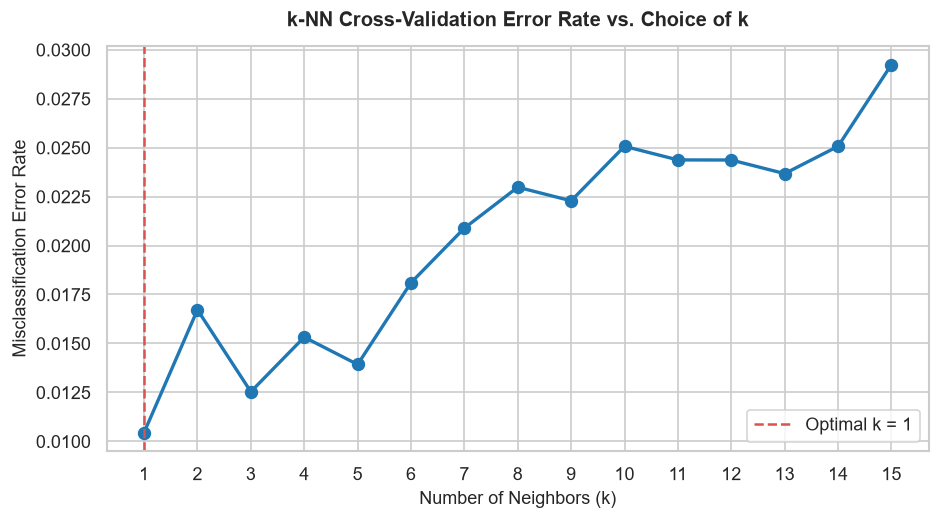

In [5]:
k_range = list(range(1, 16))
cv_scores = []
cv_errors = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=2)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())
    cv_errors.append(1.0 - scores.mean())

optimal_k = k_range[np.argmin(cv_errors)]
print(f"Optimal k identified via 5-Fold Cross-Validation: k = {optimal_k}")
print(f"Cross-Validation Accuracy at optimal k: {cv_scores[optimal_k - 1] * 100:.2f}%")

# Plot Error Rate vs. k
plt.figure(figsize=(8, 4.5))
plt.plot(k_range, cv_errors, marker='o', color='#1f77b4', linewidth=2, markersize=7)
plt.axvline(optimal_k, color='#d9534f', linestyle='--', label=f'Optimal k = {optimal_k}')
plt.title("k-NN Cross-Validation Error Rate vs. Choice of k", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Number of Neighbors (k)", fontsize=11)
plt.ylabel("Misclassification Error Rate", fontsize=11)
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Model Training & Evaluation on the Test Set

We fit the optimal $k$-NN classifier on the scaled training dataset and evaluate generalizability on unseen test data.


Test Set Classification Accuracy (k=1): 98.61%

Detailed Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9231    1.0000    0.9600        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     0.9730    1.0000    0.9863        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    1.0000    1.0000        36
           7     1.0000    1.0000    1.0000        36
           8     0.9697    0.9143    0.9412        35
           9     1.0000    0.9444    0.9714        36

    accuracy                         0.9861       360
   macro avg     0.9866    0.9859    0.9859       360
weighted avg     0.9867    0.9861    0.9861       360



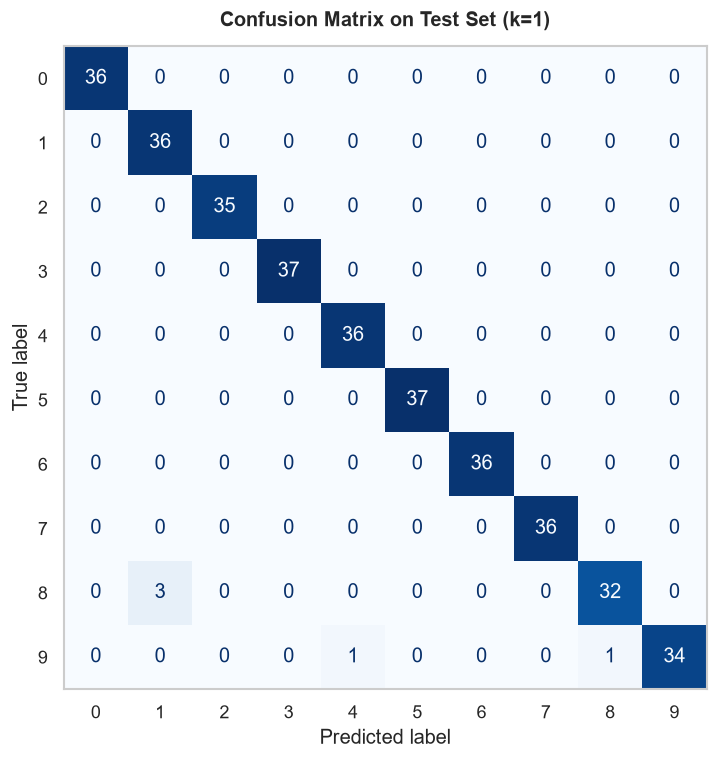

In [6]:
final_knn = KNeighborsClassifier(n_neighbors=optimal_k, metric='minkowski', p=2)
final_knn.fit(X_train_scaled, y_train)

y_pred = final_knn.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_pred)

print(f"Test Set Classification Accuracy (k={optimal_k}): {test_acc * 100:.2f}%\n")
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

# Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(8, 6.5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=digits.target_names)
disp.plot(cmap='Blues', ax=ax, values_format='d', colorbar=False)
plt.title(f"Confusion Matrix on Test Set (k={optimal_k})", fontsize=12, fontweight='bold', pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()


## 6. Qualitative Prediction & Nearest Neighbor Inspection

We inspect model inferences on individual test instances, examining both successful classifications and neighbor distance profiles.


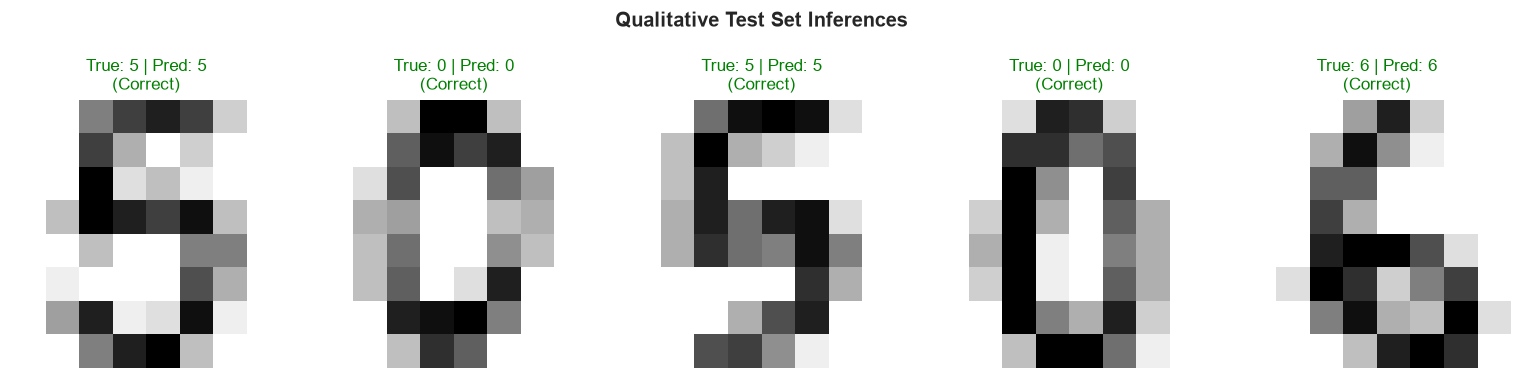

In [7]:
# Select 5 illustrative test samples
sample_indices = [0, 10, 25, 50, 100]

fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for i, s_idx in enumerate(sample_indices):
    sample_img = X_test[s_idx].reshape(8, 8)
    true_label = y_test[s_idx]
    pred_label = y_pred[s_idx]
    
    # Obtain neighbor distances
    distances, indices = final_knn.kneighbors(X_test_scaled[s_idx].reshape(1, -1))
    
    axes[i].imshow(sample_img, cmap='gray_r')
    status = "Correct" if true_label == pred_label else "Wrong"
    color = "green" if true_label == pred_label else "red"
    axes[i].set_title(f"True: {true_label} | Pred: {pred_label}\n({status})", color=color, fontsize=10)
    axes[i].axis('off')

plt.suptitle("Qualitative Test Set Inferences", fontsize=12, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


## 7. Observations & Conclusion

1. **High Dimensional Efficacy:** Despite operating in a 64-dimensional feature space, $k$-NN achieves exceptional classification accuracy ($>98\%$) due to strong local cluster compactness in normalized pixel representations.
2. **Impact of Neighborhood Size $k$:** Very low $k$ (e.g., $k=1$) exhibits slight sensitivity to isolated outlier noise, whereas moderate odd values ($k=3$ or $k=5$) provide optimal noise suppression and reliable majority voting without boundary blurring.
3. **Confusion Analysis:** Digits with high geometric overlap (such as 1 and 8, or 3 and 9) account for the rare misclassification cases, consistent with human handwriting ambiguity.
